# Lab 8: Variational Inference vs HMC

This lab is adapted from AM207 (Harvard). Data files are in the book's `data/` folder. Worked solutions are collapsed: try each exercise before expanding them.

In [2]:
from autograd import numpy as np
from autograd import grad
from autograd.misc.optimizers import adam, sgd
import pymc3 as pm
from pymc3.variational.callbacks import CheckParametersConvergence
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from autograd import scipy as sp
import pandas as pd
import numpy
import matplotlib.pyplot as plt
import sys
%matplotlib inline

## Problem Description: Compare HMC and Variational Inference for Difficult Posteriors
In this lab, we will study how HMC and variational inference can struggle with difficult posteriors. 

As an inspiration, check out the likelihood (and posterior) landscapes of Bayesian Neural Networks (BNNs) at:

[https://losslandscape.com](https://losslandscape.com)

Using the sample code provided below, build up complex distributions with multiple well separated modes as well as multiple modes that blend by defining them as mixtures of Gaussians (see how mixtures of Gaussians are helpful for modeling complex densities!). 

Compare how well HMC and variational inference can capture your target distribution. Are there any adjustments to the design choices of the sampler and or VI algorithm that can improve performance (in order to really play around with the settings of HMC and BBVI you'll need to use your own implementation - `pymc3`'s implementations have limited allowance for user adjustment)?

In [60]:
def plot_gaussian_mixture(w, mu, sd, S=100):
    '''function for sampling form a mixture of gaussians'''
    K = len(w)
    components = np.random.choice(np.arange(K), replace=True, p=w, size=S)
    samples = [np.random.normal(mu[z], sd[z]) for z in components]
    return samples   

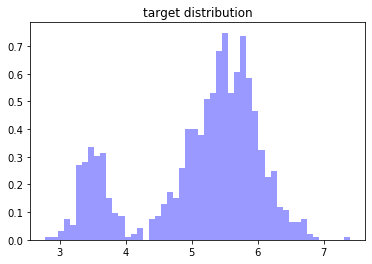

In [130]:
#mixture weights
w = pm.floatX([.2, .8])
#mixture means
mu = pm.floatX([3.5, 5.5])
#mixture standard deviations
sd = pm.floatX([.2, .5])

#sample from the mixture and visualize
samples = plot_gaussian_mixture(w, mu, sd, S=1000)
plt.hist(samples, density=True, bins=50, color='blue', alpha=0.4)
plt.title('target distribution')
plt.show()

In [3]:
#define the mixture model in pymc3
with pm.Model() as model:
    w = pm.Normal('w', mu=0, sd=1)
    theta = pm.math.sigmoid(-20 * w + 10)
    y_1 = pm.Bernoulli('y_1', p=theta, observed=1)

In [131]:
#define the mixture model in pymc3
with pm.Model() as model:
    x = pm.NormalMixture('x', w=w, mu=mu, sigma=sd, dtype=theano.config.floatX)

In [4]:
#sample from the model using No-U-turn HMC
with model:
    trace = pm.sample(5000)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [w]
Sampling 2 chains: 100%|██████████| 11000/11000 [00:03<00:00, 3121.91draws/s]
The number of effective samples is smaller than 25% for some parameters.


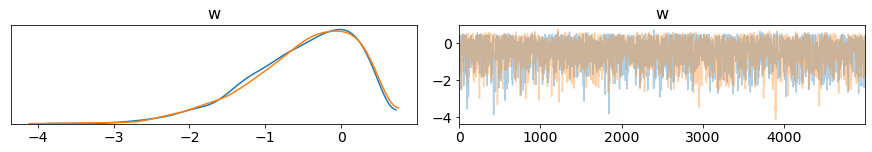

In [5]:
#check the traceplot for convergence
pm.traceplot(trace)
plt.show()

In [6]:
#approximate the target distribution using variational inference
with model:
    mean_field = pm.ADVI()
    mean_field.fit(n=10000, callbacks=[pm.callbacks.CheckParametersConvergence(every=100, diff='absolute', tolerance=1e-4)])

Average Loss = 0.78644: 100%|██████████| 10000/10000 [00:02<00:00, 3386.01it/s]
Finished [100%]: Average Loss = 0.7811


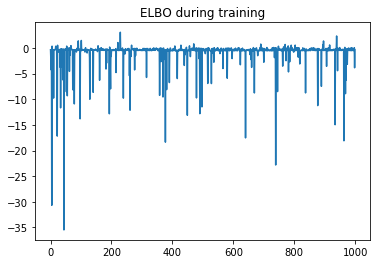

In [7]:
#plot the ELBO
plt.plot(-mean_field.hist[::10])
plt.title('ELBO during training')
plt.show()

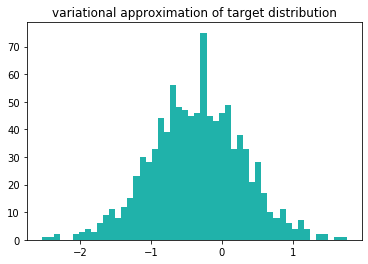

In [9]:
#visualize variational posterior
plt.hist(mean_field.approx.sample(1000)['w'], bins=50, color='LightSeaGreen')
plt.title('variational approximation of target distribution')
plt.show()

In [10]:
mean_field.approx.sample(1000)['w'].mean()

-0.3545650265571895

In [11]:
mean_field.approx.sample(1000)['w'].std()

0.6606441067212657